# Завдання 3. Кольорове зображення — три матриці
Лекція 2

## Початковий прогноз
Перші чотири пікселі верхнього рядка `[255,0,0], [0,255,0], [0,0,255], [255,255,255]`.
**Прогноз:** червоний, зелений, синій, білий. Другий рядок: жовтий, блакитний (cyan), пурпуровий, чорний. Третій рядок: темно-синій, жовто-помаранчевий, сірий, світло-синій.

Форма: (3, 4, 3)
Тип: uint8
Кількість пікселів: 12
Кількість числових елементів: 36
RGB до зміни: [ 40  80 200]
RGB після зміни: [128  80 200]


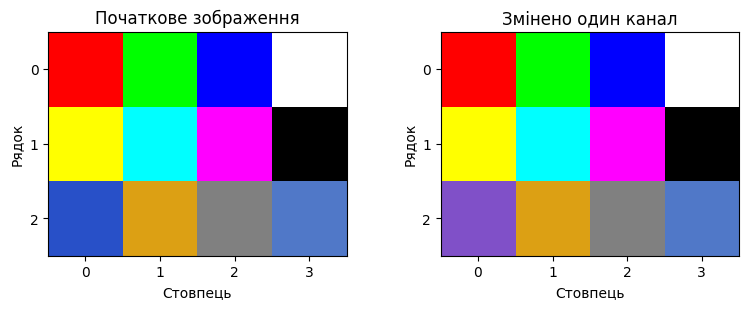

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# У кожному пікселі числа записано в порядку [R, G, B].
image = np.array([
    [[255,   0,   0], [  0, 255,   0], [  0,   0, 255], [255, 255, 255]],
    [[255, 255,   0], [  0, 255, 255], [255,   0, 255], [  0,   0,   0]],
    [[ 40,  80, 200], [220, 160,  20], [128, 128, 128], [ 80, 120, 200]]
], dtype=np.uint8)

def show_images(items):
    fig, axes = plt.subplots(1, len(items), figsize=(4 * len(items), 3))
    axes = np.atleast_1d(axes)
    for ax, (data, title) in zip(axes, items):
        if data.ndim == 2:
            ax.imshow(data, cmap="gray", vmin=0, vmax=255,
                      interpolation="nearest", origin="upper")
        else:
            ax.imshow(data, interpolation="nearest", origin="upper")
        ax.set_xticks(range(data.shape[1]))
        ax.set_yticks(range(data.shape[0]))
        ax.set_xlabel("Стовпець")
        ax.set_ylabel("Рядок")
        ax.set_title(title)
    plt.tight_layout()
    plt.show()

# Змінюйте лише параметри нижче. Використовуйте цілі числа.
row = 2
col = 0
channel = 0  # 0 — R, 1 — G, 2 — B
value = 128

if not (0 <= row < image.shape[0] and 0 <= col < image.shape[1]):
    raise ValueError("Індекс пікселя виходить за межі зображення")
if channel not in (0, 1, 2):
    raise ValueError("Індекс каналу має бути 0, 1 або 2")
if not 0 <= value <= 255:
    raise ValueError("Значення каналу має бути від 0 до 255")

changed = image.copy()
changed[row, col, channel] = value

print("Форма:", image.shape)
print("Тип:", image.dtype)
print("Кількість пікселів:", image.shape[0] * image.shape[1])
print("Кількість числових елементів:", image.size)
print("RGB до зміни:", image[row, col])
print("RGB після зміни:", changed[row, col])

show_images([
    (image, "Початкове зображення"),
    (changed, "Змінено один канал")
])

## Зміна одного каналу (піксель `row=2, col=0`, початково `[40, 80, 200]` — темно-синій)
Нижче всі дев'ять запусків виконано в циклі; щоразу змінюється лише одна складова копії початкового масиву.

In [2]:
for ch, name in enumerate("RGB"):
    for v in (0, 128, 255):
        c = image.copy()
        c[2, 0, ch] = v
        print(f"{name}={v:3d}: до {image[2,0]} -> після {c[2,0]}")

R=  0: до [ 40  80 200] -> після [  0  80 200]
R=128: до [ 40  80 200] -> після [128  80 200]
R=255: до [ 40  80 200] -> після [255  80 200]
G=  0: до [ 40  80 200] -> після [ 40   0 200]
G=128: до [ 40  80 200] -> після [ 40 128 200]
G=255: до [ 40  80 200] -> після [ 40 255 200]
B=  0: до [ 40  80 200] -> після [40 80  0]
B=128: до [ 40  80 200] -> після [ 40  80 128]
B=255: до [ 40  80 200] -> після [ 40  80 255]


### Таблиця 1
| Канал | Нове значення | RGB до зміни | Прогноз | RGB після зміни | Що спостерігали |
|---|---|---|---|---|---|
| R | 0 | [40, 80, 200] | майже без змін, трохи синіший | [0, 80, 200] | колір ледь змінився: ще синій, трохи холодніший |
| R | 128 | [40, 80, 200] | трохи світліший, фіолетовіший відтінок | [128, 80, 200] | синьо-фіолетовий |
| R | 255 | [40, 80, 200] | помітно фіолетовий/пурпуровий | [255, 80, 200] | яскравий рожево-пурпуровий |
| G | 0 | [40, 80, 200] | темніший, насиченіший синій | [40, 0, 200] | насичений синій з фіолетовим відтінком |
| G | 128 | [40, 80, 200] | світліший, блакитніший | [40, 128, 200] | світліший синій з блакитним відтінком |
| G | 255 | [40, 80, 200] | блакитний | [40, 255, 200] | яскравий бірюзово-блакитний |
| B | 0 | [40, 80, 200] | зникає синя складова, темний колір | [40, 80, 0] | дуже темний зеленувато-оливковий |
| B | 128 | [40, 80, 200] | темніший, менш насичений синій | [40, 80, 128] | приглушений сіро-синій |
| B | 255 | [40, 80, 200] | трохи яскравіший синій | [40, 80, 255] | чистіший яскравий синій |

*Якщо ваш власний прогноз відрізнявся — залишіть його в таблиці й поясніть причину.*

## Три матриці каналів і їх перестановка

**Прогноз світлих пікселів:** на R — піксель (0, 0), R=255; на G — (0, 1), G=255; на B — (0, 2), B=255.

Матриця R:
 [[255   0   0 255]
 [255   0 255   0]
 [ 40 220 128  80]]
Матриця G:
 [[  0 255   0 255]
 [255 255   0   0]
 [ 80 160 128 120]]
Матриця B:
 [[  0   0 255 255]
 [  0 255 255   0]
 [200  20 128 200]]
Форми каналів: (3, 4) (3, 4) (3, 4)


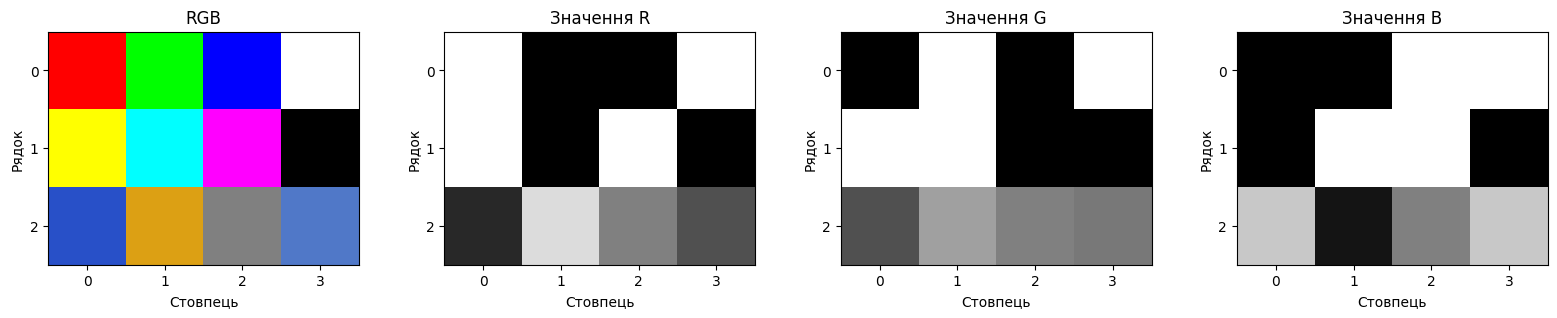

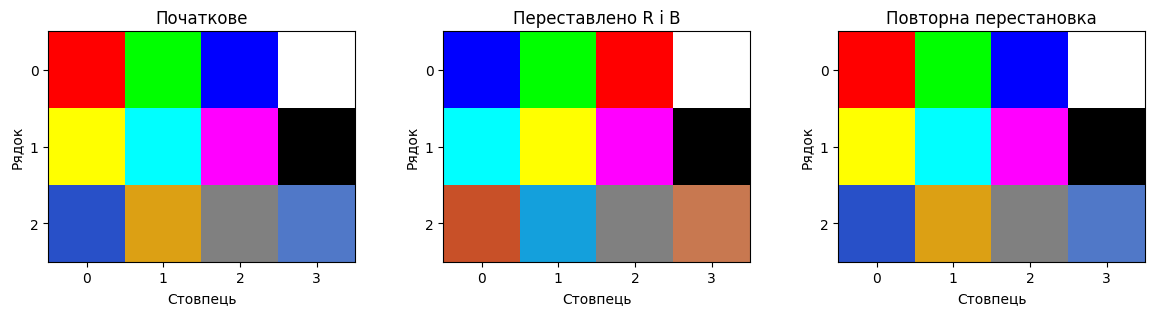

Відновлення точне: True


In [3]:
red = image[:, :, 0]
green = image[:, :, 1]
blue = image[:, :, 2]

print("Матриця R:\n", red)
print("Матриця G:\n", green)
print("Матриця B:\n", blue)
print("Форми каналів:", red.shape, green.shape, blue.shape)

show_images([
    (image, "RGB"),
    (red, "Значення R"),
    (green, "Значення G"),
    (blue, "Значення B")
])

# Змінюємо порядок каналів; координати пікселів зберігаються.
swapped = image[:, :, [2, 1, 0]]
restored = swapped[:, :, [2, 1, 0]]

show_images([
    (image, "Початкове"),
    (swapped, "Переставлено R і B"),
    (restored, "Повторна перестановка")
])
print("Відновлення точне:", np.array_equal(image, restored))

In [4]:
for r, c in [(0, 0), (2, 0)]:
    print(f"({r},{c}): до {image[r,c]} -> після {swapped[r,c]}")

(0,0): до [255   0   0] -> після [  0   0 255]
(2,0): до [ 40  80 200] -> після [200  80  40]


### Результати
- На зображеннях каналів світлі там, де значення каналу велике: R — (0,0), (1,0), (1,2), (0,3); G — (0,1), (1,0), (1,1), (0,3); B — (0,2), (1,1), (1,2), (0,3). Білий піксель (0,3) світлий на всіх трьох.
- Два пікселі до й після перестановки:
  - (0, 0): `[255, 0, 0]` → `[0, 0, 255]` (червоний став синім);
  - (2, 0): `[40, 80, 200]` → `[200, 80, 40]` (темно-синій став помаранчево-коричневим).
- `np.array_equal(image, restored)` дає `True`: перестановка R↔B — це взаємно однозначне перетворення, яке лише міняє місцями дві складові кожного пікселя й нічого не втрачає. Повторна перестановка повертає кожну складову на місце.

## Два способи перетворення на градації сірого

**Прогноз:** просте середнє для чистих червоного, зеленого й синього дасть однакове значення (255/3 ≈ 85). Зважена сума дасть різні значення: найбільше для зеленого, середнє для червоного, найменше для синього.

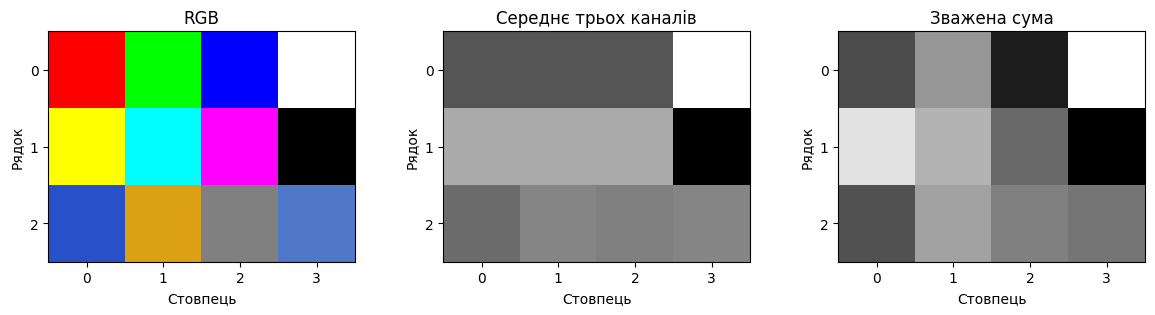

Піксель (0, 0): RGB=[255   0   0], середнє=85, зважене=76
Піксель (0, 1): RGB=[  0 255   0], середнє=85, зважене=150
Піксель (0, 2): RGB=[  0   0 255], середнє=85, зважене=29
Піксель (2, 2): RGB=[128 128 128], середнє=128, зважене=128
RGB shape = (3, 4, 3) dtype = uint8 size = 36 nbytes = 36
Середнє shape = (3, 4) dtype = uint8 size = 12 nbytes = 12
Зважене shape = (3, 4) dtype = uint8 size = 12 nbytes = 12


In [5]:
# Обчислюємо у float, щоб суми не переповнювали uint8.
work = image.astype(np.float64)

gray_mean_float = work.mean(axis=2)
weights = np.array([0.299, 0.587, 0.114])
gray_weighted_float = (work * weights).sum(axis=2)

# Обидва результати зберігаємо в одному типі для порівняння пам'яті.
gray_mean = np.clip(np.rint(gray_mean_float), 0, 255).astype(np.uint8)
gray_weighted = np.clip(np.rint(gray_weighted_float), 0, 255).astype(np.uint8)

show_images([
    (image, "RGB"),
    (gray_mean, "Середнє трьох каналів"),
    (gray_weighted, "Зважена сума")
])

for row, col in [(0, 0), (0, 1), (0, 2), (2, 2)]:
    print(
        f"Піксель ({row}, {col}): RGB={image[row, col]}, "
        f"середнє={gray_mean[row, col]}, "
        f"зважене={gray_weighted[row, col]}"
    )

for name, data in [
    ("RGB", image),
    ("Середнє", gray_mean),
    ("Зважене", gray_weighted)
]:
    print(
        name,
        "shape =", data.shape,
        "dtype =", data.dtype,
        "size =", data.size,
        "nbytes =", data.nbytes
    )

In [6]:
for r, c in [(0, 0), (0, 1), (0, 2), (2, 2)]:
    print((r, c), "середнє до округлення:", gray_mean_float[r, c],
          "| зважене до округлення:", gray_weighted_float[r, c])

(0, 0) середнє до округлення: 85.0 | зважене до округлення: 76.24499999999999
(0, 1) середнє до округлення: 85.0 | зважене до округлення: 149.685
(0, 2) середнє до округлення: 85.0 | зважене до округлення: 29.07
(2, 2) середнє до округлення: 128.0 | зважене до округлення: 127.99999999999999


### Таблиця 2
| Піксель | Координати | RGB | Прогноз для середнього | Середнє, після округлення | Прогноз для зваженої суми | Зважена сума, після округлення |
|---|---|---|---|---|---|---|
| Чистий червоний | (0, 0) | [255, 0, 0] | 85 | 85 | ≈ 76 (0.299·255) | 76 |
| Чистий зелений | (0, 1) | [0, 255, 0] | 85 | 85 | ≈ 150 (0.587·255) | 150 |
| Чистий синій | (0, 2) | [0, 0, 255] | 85 | 85 | ≈ 29 (0.114·255) | 29 |
| Сірий | (2, 2) | [128, 128, 128] | 128 | 128 | 128 | 128 |

### Ручні обчислення
- Червоний `[255, 0, 0]`: середнє = 255/3 = **85.0** → 85; зважена = 0.299·255 = **76.245** → 76.
- Зелений `[0, 255, 0]`: середнє = 255/3 = **85.0** → 85; зважена = 0.587·255 = **149.685** → 150.
- (Синій для перевірки: 0.114·255 = 29.07 → 29.)

Значення в масиві збігаються з округленими результатами (76.245 → 76, 149.685 → 150).

**Сірий піксель (2, 2):** у нього R = G = B = 128. Середнє = 128. Зважена сума = 128·(0.299 + 0.587 + 0.114) = 128·1 = 128. Коефіцієнти в сумі дають 1, тому для рівних каналів обидва способи дають те саме число. У чистих основних кольорів канали різні, тому способи розходяться.

### Таблиця 3
| Зображення | shape | dtype | Кількість пікселів | size | nbytes, байтів |
|---|---|---|---|---|---|
| RGB | (3, 4, 3) | uint8 | 12 | 36 | 36 |
| Сіре: просте середнє | (3, 4) | uint8 | 12 | 12 | 12 |
| Сіре: зважена сума | (3, 4) | uint8 | 12 | 12 | 12 |

## Відповіді на питання
1. `image[1, 2]` — повний RGB-вектор піксела в рядку 1, стовпці 2: `[255, 0, 255]` (пурпуровий). `image[1, 2, 0]` — одне число, значення каналу R цього піксела: `255`.
2. Ні. Виділення одного каналу бере лише одну складову (наприклад, `image[:, :, 0]`), а решту двох ігнорує. Перетворення на сіре об'єднує всі три канали в одне число (середнім або зваженою сумою).
3. Перестановка R↔B лише міняє місцями складові, тому це взаємно однозначне перетворення, і повторна перестановка його скасовує. Перетворення на сіре зводить три числа до одного, тож інформація втрачається. Наприклад, червоний `[255, 0, 0]`, зелений `[0, 255, 0]` і синій `[0, 0, 255]` дають для середнього те саме 85, і за цим числом не можна сказати, який з трьох кольорів був початковим.
4. Кількість пікселів не змінилася (12). Кількість числових елементів зменшилась з 36 до 12 (у 3 рази), і при однаковому `uint8` (1 байт на число) `nbytes` також зменшився з 36 до 12 байтів.

## Висновок
Кольорове зображення — це масив форми (висота, ширина, 3), тобто три матриці каналів R, G, B. Зміна однієї складової змінює колір піксела передбачувано: збільшення R додає червоного, G — зеленого, B — синього. Перестановка каналів оборотна, а перетворення на сіре — ні, бо зводить три числа до одного. Просте середнє дає однакове сіре для чистих основних кольорів, а зважена сума враховує різний внесок каналів (зелений найсвітліший, синій найтемніший). Для сірих пікселів (R = G = B) обидва способи збігаються. Перехід до градацій сірого зменшує обсяг даних рівно втричі за тієї самої кількості пікселів.